# Retail Sales Analysis
This starter uses synthetic demonstration data. Replace it if your internship specifies an official dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv('../dataset/retail_sales.csv', parse_dates=['OrderDate'])
df.head()

,OrderID,OrderDate,CustomerID,Region,Product,Category,Quantity,UnitPrice,Sales
0,ORD-0001,2025-05-06,CUST-015,South,Mouse,Accessories,1,581,581
1,ORD-0002,2025-10-30,CUST-028,North,Mouse,Accessories,5,389,1945
2,ORD-0003,2025-04-30,CUST-033,North,Laptop,Electronics,1,52164,52164
3,ORD-0004,2025-04-23,CUST-029,East,Monitor,Electronics,5,12873,64365
4,ORD-0005,2025-06-24,CUST-018,South,Laptop,Electronics,2,58848,117696


In [2]:
print('Shape:', df.shape)
print('\nMissing values:\n', df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Duplicate OrderIDs:', df['OrderID'].duplicated().sum())

Shape: (240, 9)

Missing values:
 OrderID       0
OrderDate     0
CustomerID    0
Region        0
Product       0
Category      0
Quantity      0
UnitPrice     0
Sales         0
dtype: int64

Duplicate rows: 0
Duplicate OrderIDs: 0


In [3]:
assert df['OrderID'].notna().all()
assert (df['Quantity'] > 0).all()
assert (df['UnitPrice'] >= 0).all()
print('Rows where Sales equals Quantity × UnitPrice:', (df['Sales'] == df['Quantity'] * df['UnitPrice']).sum(), 'of', len(df))

Rows where Sales equals Quantity × UnitPrice: 240 of 240


In [4]:
print('Total sales:', df['Sales'].sum())
print('Total orders:', df['OrderID'].nunique())
print('Units sold:', df['Quantity'].sum())
print('Average sale:', df['Sales'].mean())
print('Unique customers:', df['CustomerID'].nunique())

Total sales: 6245738
Total orders: 240
Units sold: 702
Average sale: 26023.908333333333
Unique customers: 40


,Category,Sales
1,Electronics,5157394
2,Furniture,849033
0,Accessories,239311


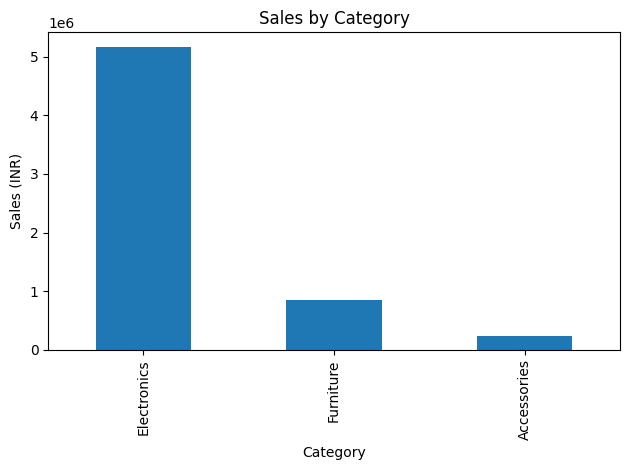

In [5]:
category = df.groupby('Category', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
display(category)
category.plot(kind='bar', x='Category', y='Sales', legend=False, title='Sales by Category')
plt.ylabel('Sales (INR)'); plt.tight_layout(); plt.show()

,Region,Sales
1,North,1884991
0,East,1732466
3,West,1459777
2,South,1168504


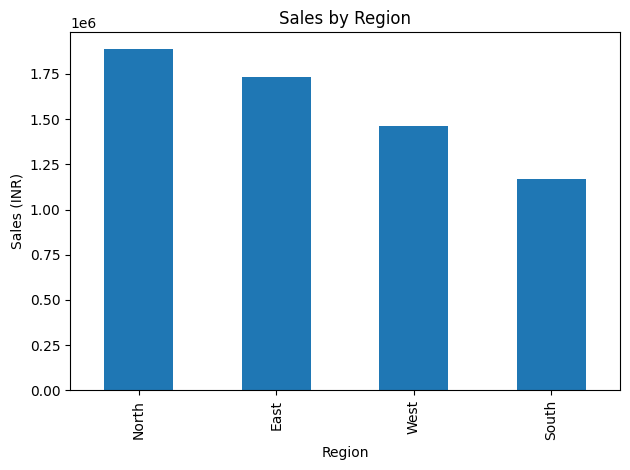

In [6]:
region = df.groupby('Region', as_index=False)['Sales'].sum().sort_values('Sales', ascending=False)
display(region)
region.plot(kind='bar', x='Region', y='Sales', legend=False, title='Sales by Region')
plt.ylabel('Sales (INR)'); plt.tight_layout(); plt.show()

,Month,Sales
0,2025-01,424582
1,2025-02,529959
2,2025-03,492035
3,2025-04,969539
4,2025-05,369772
5,2025-06,682019
6,2025-07,99144
7,2025-08,494733
8,2025-09,325189
9,2025-10,376160


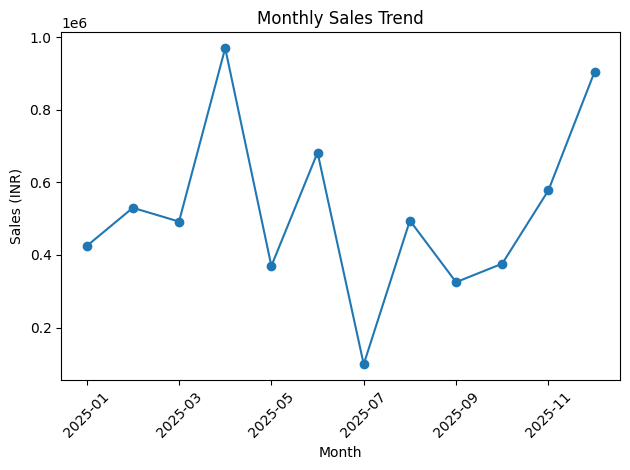

In [7]:
monthly = df.assign(Month=df['OrderDate'].dt.to_period('M').astype(str)).groupby('Month', as_index=False)['Sales'].sum()
display(monthly)
monthly.plot(kind='line', x='Month', y='Sales', marker='o', legend=False, title='Monthly Sales Trend')
plt.xticks(rotation=45); plt.ylabel('Sales (INR)'); plt.tight_layout(); plt.show()